<h1><center>Extracting Source Infromation from Gravitational Wave Data:<br>
GW170817 Case Study</center></h1>
<h2><center>Amber L. Stuver<br>
Villanova University</center></h2>

<center><a href = "mailto: amber.stuver@ligo.org">amber.stuver@ligo.org</a></center>

Neste exercício, demonstraremos como informações astrofísicas sobre a fonte podem ser extraídas de um sinal de onda gravitacional. O sinal utilizado aqui é uma aproximação do sinal GW170817, proveniente da fusão de um sistema binário de estrelas de nêutrons que também foi observado por meio de observações eletromagnéticas. Você pode ler mais sobre esse evento <a href='https://www.ligo.org/science/Publication-GW170817BNS/index.php'>aqui</a>.

<b>ROTEIRO:</b>
1. Importar bibliotecas, definir constantes e carregar os dados da onda gravitacional
2. Determinar a frequência de cada ciclo no sinal
3. Determinar a massa *chirp*
4. Fazer algumas suposições para determinar as massas dos componentes
5. Determinar a separação orbital
6. Determinar a velocidade tangencial
7. Conclusão
8. Links para literatura relevante

<b>Observe</b> que esta atividade utiliza equações derivadas da linearização da relatividade geral, a qual é válida apenas no regime de campo fraco — isto é, onde a gravidade é fraca. Próximo à fase de fusão do sinal de onda gravitacional, essa aproximação deixa de ser válida. Nesse ponto, é necessário um tratamento completo da relatividade.

<h2>1.Importe bibliotecas, defina constantes e carregue dados de ondas gravitacionais:</h2>

Vamos começar fazendo a pergunta: 

<b>"Como os cientistas sabem o que produziu uma onda gravitacional que detectaram?"</b> 

A resposta é que a informação está codificada no próprio sinal, e aqui começaremos a aprender como decodificá-la. Houve grande entusiasmo em torno da fusão de um sistema binário de estrelas de nêutrons observada em agosto de 2017 pelo LIGO (ondas gravitacionais) e pelos satélites Fermi e INTEGRAL (raios gama), seguida rapidamente por observações em outros comprimentos de onda (óptico, infravermelho, ultravioleta, rádio, raios-X) feitas por astrônomos de todo o mundo. De todas as observações realizadas desse evento, apenas os dados de ondas gravitacionais forneceram as informações necessárias para identificar que se tratava de uma fusão de estrelas de nêutrons binárias.

<b>Vamos percorrer as etapas básicas necessárias para chegar a essa conclusão.</b> 

Todos esses resultados são estimativas, uma vez que trabalhamos com uma aproximação do sinal (com precisão de apenas $1\times10^{-24}$ na deformação/amplitude relativa) e não utilizamos a relatividade geral completa; ainda assim, esses resultados são extremamente valiosos para todos os aspirantes a astrônomos de ondas gravitacionais!

Primeiro, vamos carregar as bibliotecas necessárias, definir as constantes requeridas e carregar uma aproximação do sinal GW170817...

--2026-10-05 16:22:41--  https://raw.githubusercontent.com/jkanner/aapt/master/GW170817.txt
Connecting to 192.168.200.1:3128... connected.
Proxy request sent, awaiting response... 200 OK
Length: 4493326 (4.3M) [text/plain]
Saving to: ‘GW170817.txt.2’

GW170817.txt.2      100%[===================>]   4.29M  --.-KB/s    in 0.05s   

2026-10-05 16:22:47 (83.9 MB/s) - ‘GW170817.txt.2’ saved [4493326/4493326]

The number of samples in the data is 232609.


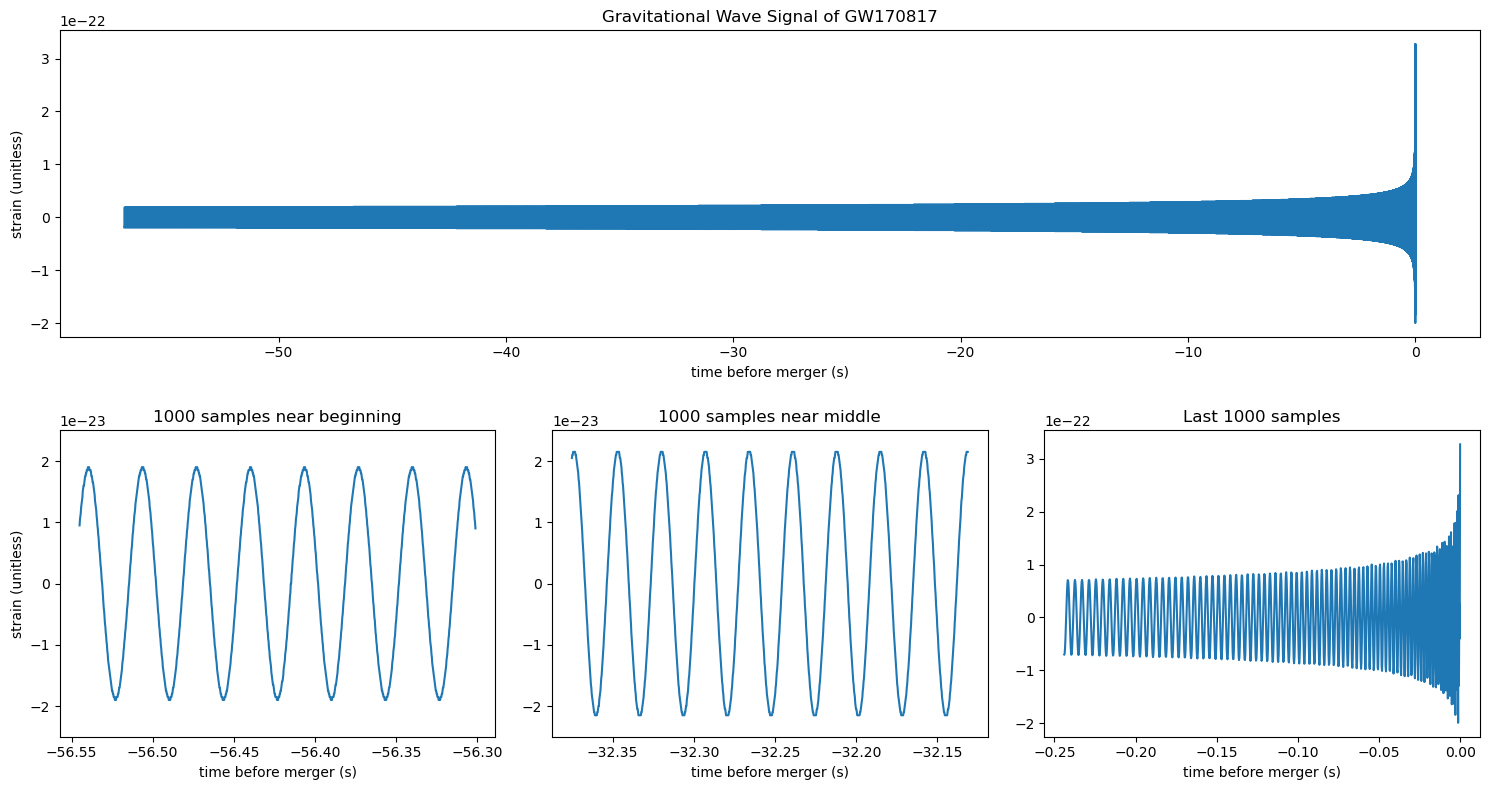

In [1]:
import numpy as np
from scipy.stats import linregress
import matplotlib.pyplot as plt
%matplotlib inline 

# CONSTANTS:
G = 6.67408e-11
c = 299792458 # m/s
Msun = 1.989e+30 # kg
r_Sun = 695.508e+6 # m
#Earth_Moon = 384472282    # m - helpful to convert orbital sep., but not needed
#r_Earth = 6.371e+6        # m - helpful to convert orbital sep., but not needed
#m2mi = 1609.344           # m - helpful to convert orbital sep., but not needed


# LOAD WAVEFORM DATA:
! wget https://raw.githubusercontent.com/jkanner/aapt/master/GW170817.txt
t, h = np.loadtxt('GW170817.txt', unpack=True)
print('The number of samples in the data is {}.'.format(len(h)))

# PLOT ALL THE DATA
plt.figure(figsize=(15,8))
plt.subplot(211)
plt.plot(t, h) # plot all of the data
plt.grid(which='minor')
plt.title('Gravitational Wave Signal of GW170817')
plt.ylabel('strain (unitless)')
plt.xlabel('time before merger (s)')

# PLOT 1000 SAMPLES NEAR THE BEGINNING
#plt.figure()
plt.subplot(234)
plt.plot(t[1000:2000], h[1000:2000])         # plot indices 1000:2000 (1000 samples)
#plt.grid(which='minor')
plt.ylim([-2.5e-23, 2.5e-23])
plt.title('1000 samples near beginning')
plt.ylabel('strain (unitless)')
plt.xlabel('time before merger (s)')

# PLOT 1000 SAMPLES NEAR THE MIDDLE
#plt.figure()
plt.subplot(235)
plt.plot(t[100000:101000], h[100000:101000]) # plot indices 100000:101000 (1000 samples)
#plt.grid(which='minor')
plt.ylim([-2.5e-23, 2.5e-23])
plt.title('1000 samples near middle')
#plt.ylabel('strain (unitless)')
plt.xlabel('time before merger (s)')

# PLOT 1000 SAMPLES AT THE END
#plt.figure()
plt.subplot(236)
plt.plot(t[-1000:], h[-1000:]) # plot last 1000 samples
plt.title('Last 1000 samples')
#plt.grid(which='minor')
#plt.ylabel('strain (unitless)')
plt.xlabel('time before merger (s)')
plt.tight_layout()
plt.savefig('fig1.eps', format='eps')

Como se pode observar neste sinal, a amplitude aumenta com o tempo. Ao examinar mais de perto segmentos menores do sinal (os três últimos gráficos de 1000 amostras, correspondentes a trechos próximos ao início, ao meio e ao fim do sinal), percebe-se também que o período diminui com o tempo — sendo essa a grandeza importante. Esse tipo de forma de onda é conhecido como "chirp" (ou "gorjeio"), uma vez que o canto de um pássaro apresenta características semelhantes.

Podemos utilizar essa informação e a terceira lei de Kepler para estabelecer nossa primeira hipótese. Lembre-se da equação da lei de Kepler:

\begin{equation}
P_{orb}^{2} = R^{3}\bigg[ \frac{4\pi^{2}}{G(m_{1}+m_{2})} \bigg]
\end{equation}

onde $P_{orb}$ é o período orbital e $R$ é o raio orbital (semieixo maior, no caso de órbitas elípticas).

<b>Observe que</b>, como a ordem mais baixa de radiação gravitacional é quadrupolar, o período de uma onda gravitacional, $P_{gw}$, corresponde à metade do período orbital do sistema:

\begin{equation}
P_{orb} = 2P_{gw}
\end{equation}

OBSERVAÇÕES SOBRE O SINAL:

1. Quando dois objetos orbitam um ao outro no espaço, eles irradiam energia e momento angular na forma de ondas gravitacionais, o que reduz a separação orbital entre eles ($R$, na lei de Kepler). Simultaneamente, o período também diminui.
2. Devido à redução da separação orbital, as massas passam a acelerar mais rapidamente. Como as ondas gravitacionais são geradas por massas em aceleração, isso resulta na produção de ondas gravitacionais mais intensas (de maior amplitude).

<b>Portanto, com base em nossos conhecimentos de física, levantamos a hipótese de que a fonte deste sinal é um sistema binário.</b>

Obter mais informações sobre a massa desse sistema nos permitirá determinar se ele é composto por buracos negros, estrelas de nêutrons ou estrelas comuns. Vamos assumir que ambos os objetos no sistema binário são do mesmo tipo — isto é, dois buracos negros, duas estrelas de nêutrons ou duas estrelas comuns.

Para isso, precisaremos ser capazes de medir como o período ou a frequência da onda gravitacional varia ao longo do tempo. Uma maneira simples de fazer isso é supor que a taxa de variação é desprezível durante um ciclo e determinar a duração de ciclos individuais. Faremos isso identificando os instantes em que o sinal cruza o valor zero...

<h2>2. Determine a frequência de cada ciclo no sinal:</h2>

Para encontrar as passagens pelo zero, identificamos os índices dos elementos com valor negativo e, em seguida, determinamos o intervalo entre esses índices. Índices adjacentes apresentam um intervalo de 1. Para localizar onde ocorre a transição do valor negativo para o positivo, identificamos os pontos onde os índices não são adjacentes. Utilizamos esses índices não adjacentes para determinar os instantes de início de novos períodos. Isso nos permite, então, medir diretamente $P_{gw}$ e a frequência da onda gravitacional, $f$.

<b>Nota:</b> Este é um excelente exercício de programação para que os alunos desenvolvam seu próprio algoritmo de detecção de passagens pelo zero. Esta não é a única implementação capaz de produzir resultados precisos.

In [2]:
# DETERMINE FREQUENCY FROM THE ZERO CROSSINGS:
# find indices of negative numbers
ndx_neg = np.where(h != abs(h))[0] 

# find interval between indices of negative numbers
diff_ndx = np.diff(ndx_neg)

# find last negative value in every interval
last_neg = np.where(diff_ndx > 1)[0] 

# index of begining of each period
ndx_period = ndx_neg[last_neg]

# determine times of new periods
t_period = t[ndx_period]

# determine the period of each cycle
Pgw = np.diff(t_period) 

# fix t_period to be the same length as Pgw
t_period = t_period[1:]

# determine the frequency of each cycle
f = 1/Pgw 

<h2>3. Determine a massa de chirp:</h2>

A massa de *chirp* é uma grandeza que aparece frequentemente na física de ondas gravitacionais e é necessária para descrever como o período de um sinal de espiralamento (*inspiral*) varia com o tempo, tal como observamos em nosso sinal. A massa de *chirp*, $M_{c}$, é definida como:

\begin{equation}
M_{c} = \frac{(m_{1}m_{2})^{\frac{3}{5}}}{(m_{1}+m_{2})^{\frac{1}{5}}}
\end{equation}

onde $m_{1}$ e $m_{2}$ são as massas dos componentes do sistema binário. Um ponto importante a destacar sobre a massa de *chirp* é que ela não nos informa sobre as massas individuais dos componentes. <b>Para uma mesma massa de *chirp*, podemos ter desde um sistema de massas iguais até razões de massa extremamente diferentes.</b> Apenas uma análise completa baseada na relatividade geral permite separar verdadeiramente essas variáveis, mas podemos adotar algumas suposições simplificadoras que nos serão úteis mais adiante.

A massa de *chirp* pode ser extraída de um sinal de onda gravitacional medindo-se a derivada temporal da frequência da onda gravitacional, $\dot{f}$:

\begin{equation}
M_{c} = \frac{c^{3}}{G}\bigg[ \Big( \frac{5}{96} \Big)^{3} \pi^{-8} f^{-11} \dot{f}^{3} \bigg]^{\frac{1}{5}}
\end{equation}

Embora esse método seja eficaz, podem surgir problemas de cálculo caso $\dot{f}$ apresente um valor negativo. Embora isso não deva ocorrer na natureza, dados ruidosos ou erros de arredondamento podem resultar em um $\dot{f}$ negativo. Portanto, adotaremos uma abordagem diferente; <b>determinaremos a massa de *chirp* a partir da inclinação de $f^{-\frac{8}{3}}$.</b>

Ao integrar a última expressão, obtém-se o seguinte resultado:

\begin{equation}
f^{-\frac{8}{3}} = \frac{(8\pi)^{\frac{5}{3}}}{5} \Big( \frac{GM_{c}}{c^{3}} \Big) (t_{c} - t)
\end{equation}

onde $t_{c}$ é o instante da coalescência. Visto que a origem temporal do nosso conjunto de dados é o evento de fusão, temos $t_{c}=0$; ao derivar essa expressão, verifica-se que a massa de *chirp*, $M_{c}$, é proporcional à inclinação de $f^{-\frac{8}{3}}$:

\begin{equation}
\frac{\mathrm{d}f^{-\frac{8}{3}}}{\mathrm{d}t}=\textrm{inclinação}=s=-\frac{(8\pi)^{\frac{5}{3}}}{5} \Big( \frac{GM_{c}}{c^{3}} \Big)
\end{equation}

Definindo a inclinação como a variável $s$, a massa de *chirp* é então dada por:

\begin{equation}
M_{c} = \frac{c^{3}}{ G(8\pi)^{\frac{8}{5}} }\big( -5s \big)^{\frac{3}{5}}
\end{equation}


The chirp mass is 1.176 solar masses.
  (For reference, the published chirp mass of GW170817 is 1.186 solar masses.)



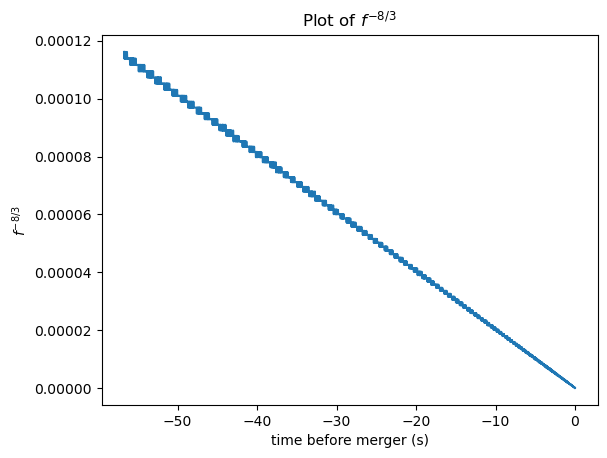

In [3]:
# DETERMINE CHIRP MASS:
f83 = f**-(8/3) # make this its own variable for ease of use

# A plot of f**-(8/3) vs t_period will show a linear trend whose slope is an estimate of the chirp mass
plt.figure(3)
plt.plot(t_period,f83)
plt.grid(which='minor')
plt.title('Plot of $f^{-8/3}$')
plt.ylabel('$f^{-8/3}$')
plt.xlabel('time before merger (s)')

# use scipy.stats.linregress (imported as lingress), to find the slope
slope, intercept, r_value, p_value, std_err = linregress(t_period, f83)

# uncomment below for alternate slope calculation
'''
# this is straightforward but less accurate...
dx = np.diff(t_period)
dy = np.diff(f83)
slopes = dy/dx
slope = np.mean(slopes)
'''

# chirp mass in kg
mc = c**3 * G**(-1) * (8*np.pi)**(-8/5) * (-5 * slope)**(3/5) # kg
# chirp mass in Msun
mc_solar = mc/Msun
print('The chirp mass is {:0.3f} solar masses.'.format(mc_solar))
print('  (For reference, the published chirp mass of GW170817 is 1.186 solar masses.)\n')

Abaixo, apresenta-se um gráfico das massas dos buracos negros e estrelas de nêutrons observados até o momento da detecção do evento GW170817 (agosto de 2017). Com base nisso, observa-se que essa "massa de *chirp*" — uma combinação das massas dos componentes — é muito inferior à de qualquer sistema de buracos negros já observado. Prosseguiremos assumindo tratar-se de um par de estrelas de nêutrons. Se estivermos corretos, o cálculo da separação orbital resultará em um valor muito menor do que o raio de uma estrela típica. Voltaremos a esse assunto mais adiante...

![Mass_plot_black_no_gap.png](https://raw.githubusercontent.com/jkanner/aapt/master/Mass_plot_black_no_gap.png)

<h2>4. Faça algumas suposições para determinar as massas dos componentes:</h2>

Se conhecemos a massa de *chirp* e podemos fazer uma suposição sobre uma das massas dos componentes, podemos determinar a outra massa componente.

Como a massa de *chirp* é pequena, é improvável que se trate de um sistema binário de buracos negros. Vamos supor que $m_{1}$ seja 1,4 $M_{Sol}$. Essa é uma massa típica para uma estrela de nêutrons, também conhecida como limite de Chandrasekhar. (Verificaremos se se trata de uma estrela de nêutrons ou de uma estrela comum ao calcular a escala da separação orbital.) A solução para $m_{2}$ em termos da massa de *chirp*, $M_{c}$, é:

\begin{equation}
0 = \Big(\frac{1}{M_{c}^{5}}\Big)m_{2}^{3} + \big(0\big)m_{2}^{2} + \Big(-\frac{1}{m_{1}^{3}}\Big)m_{2} + \Big(-\frac{1}{m_{1}^{2}}\Big)
\end{equation}

Esta é uma equação cúbica. Utilizando a notação:

\begin{equation}
0 = ax^{3} + bx^{2} + cx + d
\end{equation}

Identificando $a = \frac{1}{M_{c}^{5}}$, $b = 0$, $c = -\frac{1}{m_{1}^{3}}$ e $d = -\frac{1}{m_{1}^{2}}$, podemos usar a função `roots` da biblioteca NumPy para encontrar $m_{2}$. Você sempre obterá uma raiz real positiva e duas raízes imaginárias, dados os valores de $M_{c}$ e $m_{1}$. A solução que buscamos é a raiz real.

<b>Nota:</b> Tenha cuidado para não sobrescrever `c` (a velocidade da luz) com o coeficiente `c` aqui. No código abaixo, utilizo a letra maiúscula `C` para esse coeficiente.

In [4]:
# MAKE ASSUMTIONS TO DETERMINE INDIVIDUAL MASSES:
# assume m1 is 1.4 solar masses (typical NS)
m1 = 1.4 # solar masses

# solve cubic equ to determine m2 from chirp mass 
a = 1/mc_solar**5
b = 0 
C = -1/m1**3 # Cap C because c is speed of light
d = -1/m1**2
m2 = np.roots([a,b,C,d]) # solar masses

# sealect only the real roots
re = np.isreal(m2) # find the real root
m2 = m2[re].real # return only the real part of the real root
# select only the positive roots
pos = np.where(m2 > 0) # find the positive roots
m2 = m2[pos] # return only the real roots
print('Assuming m1 = {:0.2f} solar masses, then m2 = {:0.2f} solar masses.'.format(m1,m2[0]))
print('  (For reference, the published component masses of GW170817 are 1.46 and 1.27 solar masses.)\n')

Assuming m1 = 1.40 solar masses, then m2 = 1.30 solar masses.
  (For reference, the published component masses of GW170817 are 1.46 and 1.27 solar masses.)



Para fins de comparação, os valores publicados de todas as ondas gravitacionais detectadas até o momento (janeiro de 2019) são apresentados na tabela abaixo. O sinal de onda gravitacional em questão, GW170817, encontra-se no quadro vermelho. Os valores de $m_{1}$, $m_{2}$ e $M_{c}$ estão listados, respectivamente, na segunda, terceira e quarta (última) colunas.

Também podemos utilizar essas informações para corroborar a hipótese de que a massa *chirp* é provavelmente pequena demais para ser proveniente de um sistema binário de buracos negros. Todos os eventos de ondas gravitacionais, com exceção do GW170817 (no quadro vermelho), originaram-se de sistemas binários de buracos negros; a massa *chirp* do GW170817 é oito vezes menor do que a menor massa *chirp* produzida por uma onda gravitacional de sistema binário de buracos negros e, portanto, muito inferior à de qualquer outro sistema binário de buracos negros detectado.

![GWTC-1_Masses.png](https://raw.githubusercontent.com/jkanner/aapt/master/GWTC-1_Masses.png)

<h2>5. Determine a separação orbital:</h2>

Agora que temos uma estimativa das massas individuais do sistema, podemos usar a lei de Kepler para determinar a separação orbital entre os objetos. Resolvendo a lei de Kepler (acima) para $R$:

\begin{equation}
R = \bigg[ G(m_{1}+m_{2}) \bigg( \frac{P_{orb}}{2\pi} \bigg)^{2} \bigg]^{\frac{1}{3}}
\end{equation}

Lembre-se:

\begin{equation}
P_{orb} = 2P_{gw}
\end{equation}

Text(0.5, 1.0, 'Orbital Separation')

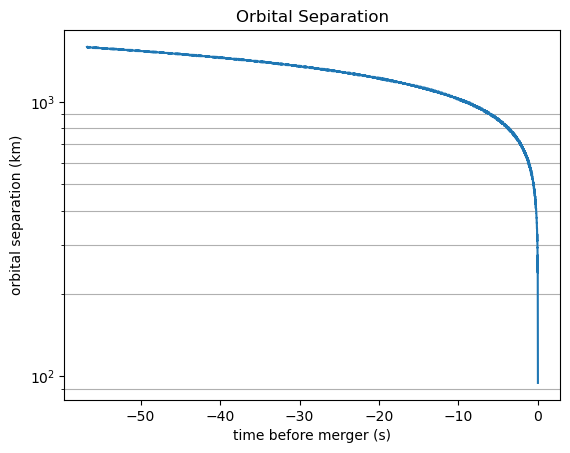

In [5]:
# DETERMINE ORBITAL SEPARATION:
Porb = 2*Pgw
mtot = (m1+m2)*Msun
R = ( G * mtot * (Porb/2*np.pi)**2 )**(1/3) # in m

# plot result
plt.figure(1)
plt.semilogy(t_period, R/1000)
plt.grid(which='minor')
plt.ylabel('orbital separation (km)')
plt.xlabel('time before merger (s)')
plt.title('Orbital Separation')

Vamos examinar a separação orbital bem no início deste sinal e compará-la com o raio do nosso Sol, uma estrela comum:

In [6]:
# compare the first (largest) orbital separation to the radius of the Sun
print('The largest orbital separation of our signal is {:0.2f}% the radius of our Sun.'.format(R[0]*100/r_Sun))

The largest orbital separation of our signal is 0.23% the radius of our Sun.


Isso corrobora nossa suposição de que se tratava de um sistema binário de estrelas de nêutrons, e não de um sistema composto por duas estrelas comuns. (Essa distância é de cerca de 1600 km, enquanto o raio típico de uma estrela de nêutrons é de aproximadamente 10 km.) Caso contrário, nosso sistema teria sofrido coalescência mais cedo e com um $P_{orb}$ muito menor.

<h2>6. Determine a velocidade tangencial:</h2>

Dados a distância orbital, $R$, e o período orbital, $P_{orb}$, podemos calcular a velocidade tangencial do sistema binário durante sua evolução:

\begin{equation}
v = 2\pi \Big( \frac{R}{P_{orb}}\Big)
\end{equation}

Text(0.5, 1.0, 'Tangential Velocity')

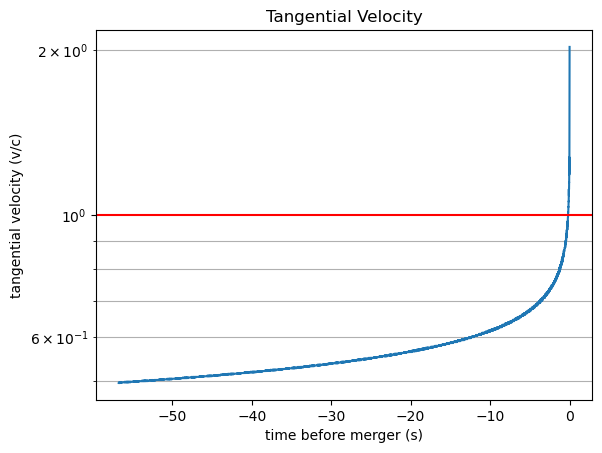

In [7]:
# DETERMINE TANGENTIAL VELOCITY:
v = 2 * np.pi * R / Porb

# plot result
plt.figure(2)
plt.semilogy(t_period, v/c)
plt.axhline(1, color='r') # plot red line indicating the speed of light (c)
plt.grid(which='minor')
plt.ylabel('tangential velocity (v/c)')
plt.xlabel('time before merger (s)')
plt.title('Tangential Velocity')

É aqui que podemos ver claramente a falha da aproximação linearizada da relatividade geral, uma vez que, à medida que nos aproximamos da fusão, nossa velocidade tangencial supera a velocidade da luz (indicada pela linha horizontal vermelha). O uso de uma abordagem completa da relatividade geral evita que isso ocorra, mas é importante perceber que nossa aproximação realmente possui limitações.

<h2>7. Conclusão:</h2>

Iniciamos este exercício com o objetivo de determinar a fonte de uma onda gravitacional a partir apenas dos dados do sinal. Ao examinar a evolução da forma de onda, identificamos características de um sinal do tipo *chirp* e, utilizando a terceira lei de Kepler, deduzimos que a fonte provavelmente era um sistema binário. Em seguida, calculamos a massa *chirp* e, como ela era da ordem de uma massa solar, concluímos que seria improvável que as massas em questão fossem de buracos negros (assumindo também que ambas eram do mesmo tipo). Isso restringiu as possibilidades para estrelas de nêutrons ou estrelas comuns. Assumimos então que uma das duas massas era de 1,4 $M_{Sol}$ — uma massa típica de estrela de nêutrons, mas também plausível para estrelas comuns. Embora isso não confirme nem descarte a hipótese de o sistema ser composto por estrelas de nêutrons, obtivemos valores para as massas dos componentes que são consistentes com os valores publicados. Calculamos também a maior separação orbital do sistema, encontrando um valor correspondente a uma fração do raio do Sol; isso reforça a ideia de que as massas componentes são muito mais densas do que uma estrela comum, levando-nos a concluir que o sistema responsável pelo sinal de onda gravitacional GW170817 era, provavelmente, um sistema binário de estrelas de nêutrons.

<h2>8. Links para literatura relevante:</h2>

- L. Rubbo, S. Larson, M. Larson, D. Ingram, "Hands-on gravitational wave astronomy: Extracting astrophysical information from simulated signals", *American Journal of Physics* **75**, 597 (2007); https://doi.org/10.1119/1.2721587.  (Accompanying activity here: http://cgwp.gravity.psu.edu/outreach/activities/handson_activity/)

- L. Burko, "Gravitational Wave Detection in the Introductory Lab", *The Physics Teacher* **55**, 288 (2017); https://doi.org/10.1119/1.4981036.

- LIGO Scientific and Virgo Collaborations, "The basic physics of the binary black hole merger GW150914", *Annalen der Physik*, **529**, No. 1-2, 1600209 (2017); https://doi.org/10.1002/andp.201600209

- H. Mathur, K. Brown, A. Lowenstein, "An analysis of the LIGO discovery based on introductory physics", *American Journal of Physics* **85**, 676 (2017); https://doi.org/10.1119/1.4985727.

- B. Farr, G. Schelbert, L. Trouille, "Gravitational wave science in the high school classroom", *American Journal of Physics*, **80**, 898 (2012); https://doi.org/10.1119/1.4738365.